# Projeto 1 — Algoritmos Avançados de Procura

por: **Ilie Iftime - 112779, Inês Cruz - 123557, Sofia Quintino - 123554**

Este notebook resolve os dois problemas do enunciado:

1. **Problema 1** — Algoritmos de procura clássica e local aplicados ao *8-Puzzle* e às *N-Rainhas*.
2. **Problema 2** — Programação linear pelo método *Simplex*.

Tudo num só ficheiro, sem utilizar bibliotecas que implementem diretamente os algoritmos. Apenas `numpy`, `pandas`, `matplotlib` para apoio.

### Setup e imports

In [ ]:
#Imports gerais
import time
import heapq
import math
import random
from collections import deque
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#Ppara os resultados estocasticos serem reprodutiveis
random.seed(42)
np.random.seed(42)

#Pasta de plots (cria se não existir)
os.makedirs("plots", exist_ok=True)

print("setup ok")

setup ok


## Parte A — Sliding Puzzle

O *sliding puzzle* clássico (8-puzzle) é um tabuleiro 3×3 com 8 peças numeradas e um espaço vazio. 
O objetivo consiste em deslizar as peças adjacentes para a casa vazia, de modo a reorganizar o tabuleiro a partir de um estado inicial aleatório até atingir uma configuração final perfeitamente ordenada.

Vamos implementar:

- **Procura não informada:** BFS e IDS
- **Procura informada:** Greedy Best-First e A\*
- **Heurísticas:** Peças fora do lugar (h1) e distância de Manhattan (h2)

### A.1 Representação do estado

Utiliza-se uma `tuple` de `tuples` (matriz imutável e `hashable`) para permitir que o estado seja inserido diretamente em conjuntos. O valor zero representa o espaço vazio.

In [ ]:
#Estado objetivo do 8-puzzle
GOAL_8 = ((1, 2, 3),
          (4, 5, 6),
          (7, 8, 0))

def find_blank(state):
    """devolve (linha, coluna) da posição do espaco vazio."""
    n = len(state)
    for r in range(n):
        for c in range(n):
            if state[r][c] == 0:
                return r, c
    return -1, -1

def neighbours(state):
    """gera os estados vizinhos válidos."""
    n = len(state)
    r, c = find_blank(state)
    res = []
    #Ordem fixa: cima, baixo, esquerda, direita
    for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
        nr, nc = r + dr, c + dc
        if 0 <= nr < n and 0 <= nc < n:
            new = [list(row) for row in state]
            new[r][c], new[nr][nc] = new[nr][nc], new[r][c]
            res.append(tuple(tuple(row) for row in new))
    return res

def print_state(s):
    for row in s:
        print(" ".join(str(v) if v != 0 else "_" for v in row))
    print()

#Teste rápido
s_teste = ((1, 2, 3), (4, 0, 5), (6, 7, 8))
print("estado de teste, blank em", find_blank(s_teste))
print(f"vizinhos: {len(neighbours(s_teste))}")

estado de teste, blank em (1, 1)
vizinhos: 4


### A.2 Heurísticas

As duas heurísticas utilizadas, ambas admissíveis (nunca sobrestimam o custo verdadeiro) são:

- **h1** — número de peças fora do lugar (excluindo o zero).
- **h2** — soma das distâncias de Manhattan de cada peça até ao seu lugar correto.

In [ ]:
def h_misplaced(state, goal):
    """h1 - numero de pecas fora do lugar."""
    n = len(state)
    count = 0
    for r in range(n):
        for c in range(n):
            v = state[r][c]
            if v != 0 and v != goal[r][c]:
                count += 1
    return count

def h_manhattan(state, goal):
    """h2 - soma das distancias de manhattan."""
    n = len(state)
    #Construir mapa de posições do goal para não andar a procurar
    goal_pos = {}
    for r in range(n):
        for c in range(n):
            goal_pos[goal[r][c]] = (r, c)
    total = 0
    for r in range(n):
        for c in range(n):
            v = state[r][c]
            if v != 0:
                gr, gc = goal_pos[v]
                total += abs(r - gr) + abs(c - gc)
    return total

#Sanity check: no goal as duas dão 0
assert h_misplaced(GOAL_8, GOAL_8) == 0
assert h_manhattan(GOAL_8, GOAL_8) == 0
print("heuristicas ok")

heuristicas ok


### A.3 Procura não informada — BFS e IDS

Breadth-First Search (BFS): Explora o espaço de estados nível a nível de forma exaustiva. Garante a devolução da solução ais curta e ótima em termos de número de movimentos, mas apresenta a desvantagem de ter um elevado custo de memória espacial. 

In [ ]:
def reconstruct(parents, end):
    """reconstrói o caminho a partir do dicionário de pais."""
    path = [end]
    while parents.get(end) is not None:
        end = parents[end]
        path.append(end)
    path.reverse()
    return path

def _result(path, explored, dt, note=""):
    return {"path": path,
            "len": (len(path) - 1) if path else None,
            "explored": explored,
            "time": dt,
            "note": note}

def bfs(start, goal, max_states=2_000_000):
    """Breadth-First Search."""
    t0 = time.perf_counter()
    if start == goal:
        return _result([start], 0, 0)
    queue = deque([start])
    visited = {start}
    parents = {start: None}
    explored = 0
    while queue:
        cur = queue.popleft()
        explored += 1
        if explored > max_states:
            return _result(None, explored, time.perf_counter() - t0, note="abortado-limite")
        for nxt in neighbours(cur):
            if nxt not in visited:
                visited.add(nxt)
                parents[nxt] = cur
                if nxt == goal:
                    return _result(reconstruct(parents, nxt), explored, time.perf_counter() - t0)
                queue.append(nxt)
    return _result(None, explored, time.perf_counter() - t0)

Iterative Deepening Search (IDS): O algoritmo funciona executando procuras em profundidade sucessivas, mas com um limite de profundidade que vai sendo incrementado iterativamente a cada tentativa até que o estado objetivo seja encontrado. Combina as vantagens da procura em profundidade (baixo consumo de memória) com as garantias da procura em largura (otimalidade da solução).  

In [5]:
def _dls(state, goal, limit, parents, visited, counter):
    """depth-limited search recursiva, para o IDS."""
    counter[0] += 1
    if state == goal:
        return state
    if limit <= 0:
        return None
    for nxt in neighbours(state):
        if nxt not in visited:
            visited.add(nxt)
            parents[nxt] = state
            res = _dls(nxt, goal, limit - 1, parents, visited, counter)
            if res is not None:
                return res
    return None

def ids(start, goal, max_depth=30):
    """Iterative Deepening Search."""
    t0 = time.perf_counter()
    total = 0
    for depth in range(max_depth + 1):
        parents = {start: None}
        visited = {start}
        counter = [0]
        end = _dls(start, goal, depth, parents, visited, counter)
        total += counter[0]
        if end is not None:
            return _result(reconstruct(parents, end), total, time.perf_counter() - t0)
    return _result(None, total, time.perf_counter() - t0, note="depth-exceeded")

### A.4 Procura informada — Greedy e A\*

Greedy Search: Seleciona o próximo estado baseando-se exclusivamente na heurística, expandindo o nó que parece estar mais próximo do objetivo. É habitualmente rápido e gasta pouca memória, mas não garante a solução ótima. 

In [ ]:
def greedy(start, goal, h):
    """Greedy Best-First Search - so a heuristica conta."""
    t0 = time.perf_counter()
    counter = 0
    heap = [(h(start, goal), counter, start)]
    visited = {start}
    parents = {start: None}
    explored = 0
    while heap:
        _, _, cur = heapq.heappop(heap)
        explored += 1
        if cur == goal:
            return _result(reconstruct(parents, cur), explored, time.perf_counter() - t0)
        for nxt in neighbours(cur):
            if nxt not in visited:
                visited.add(nxt)
                parents[nxt] = cur
                counter += 1
                heapq.heappush(heap, (h(nxt, goal), counter, nxt))
    return _result(None, explored, time.perf_counter() - t0)

A*: Combina o custo do caminho percorrido até ao momento, g(n), com o custo estimado até ao objetivo, h(n), minimizando a função objetivo f(n) = g(n) + h(n). Sendo as heurísticas utilizadas admissíveis, este algoritmo garante a devolução da solução ótima, expandindo menos nós que os métodos não informados. 

In [ ]:
def astar(start, goal, h):
    """A* - f(n) = g(n) + h(n)."""
    t0 = time.perf_counter()
    counter = 0
    heap = [(h(start, goal), 0, counter, start)]
    g_score = {start: 0}
    parents = {start: None}
    explored = 0
    while heap:
        f, g, _, cur = heapq.heappop(heap)
        explored += 1
        if cur == goal:
            return _result(reconstruct(parents, cur), explored, time.perf_counter() - t0)
        if g > g_score.get(cur, float('inf')):
            continue   #já descobrimos um caminho melhor antes
        for nxt in neighbours(cur):
            tentative = g + 1
            if tentative < g_score.get(nxt, float('inf')):
                g_score[nxt] = tentative
                parents[nxt] = cur
                counter += 1
                heapq.heappush(heap, (tentative + h(nxt, goal), tentative, counter, nxt))
    return _result(None, explored, time.perf_counter() - t0)

### A.5 Experiências

A análise considerou três estados iniciais de profundidade crescente. O cenário mais difícil (8 6 7 / 2 5 4 / 3 _ 1) possui uma solução ótima de 31 passos, o que excede a capacidade de alocação de memória do algoritmo BFS num computador modesto.

In [ ]:
#Os 3 estados iniciais
s_facil   = ((1, 2, 3), (4, 5, 6), (0, 7, 8))           #2 movimentos
s_medio   = ((1, 2, 3), (5, 0, 6), (4, 7, 8))           #4 movimentos
s_dificil = ((8, 6, 7), (2, 5, 4), (3, 0, 1))           #31 movimentos (obrigatório)

estados = {"facil": s_facil, "medio": s_medio, "dificil": s_dificil}

#Tabela de resultados
linhas_puzzle = []
for nome, s in estados.items():
    print(f"\n--- estado: {nome} ---")
    print_state(s)
    if nome != "dificil":
        r = bfs(s, GOAL_8)
        linhas_puzzle.append([nome, "BFS", r["time"], r["explored"], r["len"]])
    #IDS - no difícil não chega até 31 em tempo razoável
    if nome != "dificil":
        r = ids(s, GOAL_8, max_depth=22)
        linhas_puzzle.append([nome, "IDS", r["time"], r["explored"], r["len"]])
    for nome_h, h in [("h1", h_misplaced), ("h2", h_manhattan)]:
        r = greedy(s, GOAL_8, h)
        linhas_puzzle.append([nome, f"Greedy-{nome_h}", r["time"], r["explored"], r["len"]])
        r = astar(s, GOAL_8, h)
        linhas_puzzle.append([nome, f"A*-{nome_h}", r["time"], r["explored"], r["len"]])

df_puzzle = pd.DataFrame(linhas_puzzle,
    columns=["estado", "algoritmo", "tempo (s)", "estados explorados", "comprimento"])
df_puzzle


--- estado: facil ---
1 2 3
4 5 6
_ 7 8


--- estado: medio ---
1 2 3
5 _ 6
4 7 8


--- estado: dificil ---
8 6 7
2 5 4
3 _ 1



,estado,algoritmo,tempo (s),estados explorados,comprimento
0,facil,BFS,0.000032,3,2
1,facil,IDS,0.000027,11,2
2,facil,Greedy-h1,0.000022,3,2
3,facil,A*-h1,0.000022,3,2
4,facil,Greedy-h2,0.000040,3,2
5,facil,A*-h2,0.000037,3,2
6,medio,BFS,0.000079,19,4
7,medio,IDS,0.000232,68,4
8,medio,Greedy-h1,0.000046,5,4
9,medio,A*-h1,0.000032,5,4


#### Gráficos acerca do estado difícil

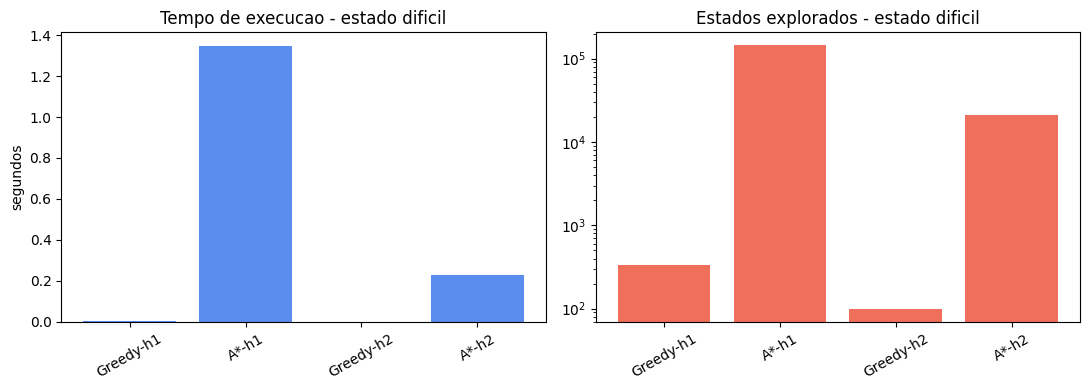

In [ ]:
sub = df_puzzle[df_puzzle["estado"] == "dificil"].copy()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(sub["algoritmo"], sub["tempo (s)"], color="#5B8DEF")
ax[0].set_title("Tempo de execucao - estado dificil")
ax[0].set_ylabel("segundos")
ax[0].tick_params(axis='x', rotation=30)

ax[1].bar(sub["algoritmo"], sub["estados explorados"], color="#EF6F5B")
ax[1].set_title("Estados explorados - estado dificil")
ax[1].set_yscale("log")
ax[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig("plots/puzzle_dificil.png", dpi=110)
plt.show()

### A.6 Discussão e perguntas

Os resultados confirmam a teoria:

BFS e IDS: Eficazes em cenários simples, mas inviáveis no estado mais complexo devido à explosão do espaço de estados e ao consequente esgotamento de memória.

Greedy Search: Destaca-se pela elevada rapidez computacional, mas sacrifica a otimalidade ao devolver caminhos consideravelmente mais longos (47 e 63 movimentos em vez de 31).

A*: Confirma-se como o algoritmo mais robusto, garantindo a descoberta do caminho ótimo de 31 movimentos através da ponderação equilibrada entre o custo real e a estimativa heurística.

Heurísticas no A* (h2 vs. h1): A Distância de Manhattan (h2) revela-se vastamente superior; por ser mais informada, permite uma poda agressiva da árvore de procura, reduzindo o tempo de execução para um quarto (~0.23s) e o número de estados expandidos em cerca de sete vezes.

## Parte B — N-Rainhas

O problema das N-Rainhas é um desafio clássico de otimização combinatória e de satisfação de restrições, que consiste em posicionar N rainhas num tabuleiro de xadrez de dimensões N x N. 
O objetivo fundamental é atingir uma configuração perfeitamente segura onde nenhuma rainha ameace qualquer outra, exigindo estritamente que não existam duas peças a partilhar a mesma linha, coluna ou diagonal.

### B.1 Representação e função objetivo

Cada estado é uma lista `board` onde `board[c]` é a linha da rainha na coluna c. Esta representação elimina automaticamente conflitos por coluna. Resta contar conflitos por linha e nas duas direções diagonais.

A função `conflicts` foi reescrita: a versão O(n²) com dois ciclos aninhados era demasiado lenta para N=50, então foram utilizados dicionários (contar quantas rainhas há em cada linha/diagonal e somar C(k,2)).

In [ ]:
def conflicts(board):
    """numero de pares (i,j) que se atacam. Queremos = 0."""
    n = len(board)
    rows = {}
    diag1 = {}   # r - c
    diag2 = {}   # r + c
    for c in range(n):
        r = board[c]
        rows[r] = rows.get(r, 0) + 1
        diag1[r - c] = diag1.get(r - c, 0) + 1
        diag2[r + c] = diag2.get(r + c, 0) + 1
    total = 0
    for d in (rows, diag1, diag2):
        for v in d.values():
            if v > 1:
                total += v * (v - 1) // 2
    return total

def random_board(n):
    return [random.randint(0, n - 1) for _ in range(n)]

def neighbours_one_move(board):
    """todos os vizinhos que diferem numa rainha."""
    n = len(board)
    res = []
    for col in range(n):
        for row in range(n):
            if row != board[col]:
                nb = list(board)
                nb[col] = row
                res.append(nb)
    return res

#Sanity check com solução conhecida do 8-rainhas
sol_8 = [0, 4, 7, 5, 2, 6, 1, 3]
assert conflicts(sol_8) == 0
print("conflicts ok, solucao do 8-rainhas:", sol_8)

conflicts ok, solucao do 8-rainhas: [0, 4, 7, 5, 2, 6, 1, 3]


### B.2 Hill Climbing (com random restart)

Hill Climbing: É um algoritmo de otimização local que avalia iterativamente as configurações vizinhas e move-se na direção de estados com maior qualidade (menor número de ataques entre rainhas). A sua principal limitação é a tendência para ficar preso em mínimos locais, falhando em encontrar a solução global caso não existam vizinhos estritamente melhores. 

In [10]:
def _res(board, score, iters, dt, ok):
    return {"board": board, "conflicts": score, "iters": iters,
            "time": dt, "ok": ok}

def hill_climbing(n, max_restarts=30, max_steps=1000):
    """Hill climbing com random restart."""
    t0 = time.perf_counter()
    total_iters = 0
    best, best_score = None, float('inf')
    for r in range(max_restarts):
        cur = random_board(n)
        cur_score = conflicts(cur)
        for step in range(max_steps):
            total_iters += 1
            if cur_score == 0:
                return _res(cur, 0, total_iters, time.perf_counter() - t0, True)
            ngh = neighbours_one_move(cur)
            scores = [conflicts(b) for b in ngh]
            mn = min(scores)
            if mn >= cur_score:
                break   # local minimum -> restart
            # escolhe aleatoriamente entre os melhores empatados
            cands = [b for b, s in zip(ngh, scores) if s == mn]
            cur = random.choice(cands)
            cur_score = mn
        if cur_score < best_score:
            best_score = cur_score
            best = cur
    return _res(best, best_score, total_iters, time.perf_counter() - t0, best_score == 0)

### B.3 Stochastic Beam Search

Stochastic Beam Search: Em vez de manter apenas um estado na memória, o algoritmo rastreia simultaneamente $k$ estados (definidos pelo parâmetro beam width). Em cada iteração, após gerar todos os sucessores, seleciona estocasticamente os $k$ estados da geração seguinte com base numa probabilidade proporcional a 1/(1+conflitos), penalizando assim as configurações com maior número de colisões. Esta amostragem ponderada garante uma maior diversidade na exploração do espaço de estados e evita a convergência prematura para mínimos locais.

In [11]:
def stochastic_beam(n, beam_width=20, max_iters=200):
    """Stochastic Beam Search."""
    t0 = time.perf_counter()
    beam = [random_board(n) for _ in range(beam_width)]
    iters = 0
    for _ in range(max_iters):
        iters += 1
        for b in beam:
            if conflicts(b) == 0:
                return _res(b, 0, iters, time.perf_counter() - t0, True)
        all_succ = []
        for b in beam:
            all_succ.extend(neighbours_one_move(b))
        scores = [conflicts(s) for s in all_succ]
        weights = [1.0 / (1 + s) for s in scores]
        beam = random.choices(all_succ, weights=weights, k=beam_width)
    best = min(beam, key=conflicts)
    return _res(best, conflicts(best), iters,
                time.perf_counter() - t0, conflicts(best) == 0)

### B.4 Simulated Annealing

Simulated Annealing: Esta variante do hill climbing mitiga a estagnação em mínimos locais ao aceitar transições subótimas com uma probabilidade de $\exp(-\Delta/T)$. À medida que a temperatura global ($T$) diminui geometricamente, a probabilidade de aceitar estas regressões decresce progressivamente, promovendo uma transição suave de uma fase inicial de forte exploração para um comportamento puramente ganancioso e conservador na etapa final da procura.

In [ ]:
def simulated_annealing(n, T0=10.0, alpha=0.995, T_min=1e-3, max_iters=10000):
    """Simulated Annealing."""
    t0 = time.perf_counter()
    cur = random_board(n)
    cur_score = conflicts(cur)
    best, best_score = list(cur), cur_score
    T = T0
    iters = 0
    while T > T_min and iters < max_iters:
        iters += 1
        if cur_score == 0:
            return _res(cur, 0, iters, time.perf_counter() - t0, True)
        #gera 1 vizinho aleatório (mais barato que gerar todos)
        col = random.randint(0, n - 1)
        new_row = random.randint(0, n - 1)
        if new_row == cur[col]:
            new_row = (new_row + 1) % n
        nb = list(cur)
        nb[col] = new_row
        nb_score = conflicts(nb)
        delta = nb_score - cur_score
        if delta < 0 or random.random() < math.exp(-delta / T):
            cur, cur_score = nb, nb_score
            if cur_score < best_score:
                best, best_score = list(cur), cur_score
        T *= alpha
    return _res(best, best_score, iters, time.perf_counter() - t0, best_score == 0)

### B.5 Tabu Search

Tabu Search: A maior função do notebook — mas com razão. Uma extensão da procura local que utiliza uma estrutura de memória a curto prazo (a tabu list) para registar os últimos estados ou movimentos visitados. Ao proibir o retorno a esses estados durante um determinado número de iterações, força o algoritmo a explorar novas regiões do espaço de estados, facilitando a fuga de mínimos locais.

In [ ]:
def tabu_search(n, tabu_size=20, max_iters=1500, no_improve_limit=200):
    """Tabu Search com aspiracao + restart."""
    t0 = time.perf_counter()
    cur = random_board(n)
    cur_score = conflicts(cur)
    best, best_score = list(cur), cur_score
    tabu = deque(maxlen=tabu_size)
    iters = 0
    no_improve = 0

    while iters < max_iters:
        iters += 1
        if best_score == 0:
            return _res(best, 0, iters, time.perf_counter() - t0, True)

        #gerar todos os vizinhos a um movimento de distância
        n_local = len(cur)
        cands = []
        for col in range(n_local):
            for row in range(n_local):
                if row == cur[col]:
                    continue
                nb = list(cur)
                nb[col] = row
                sc = conflicts(nb)
                move = (col, row)
                #critério de aspiração: aceita tabu só se melhora o melhor global
                is_tabu = move in tabu
                if is_tabu and sc >= best_score:
                    continue
                cands.append((sc, nb, move))

        if not cands:
            #toda a vizinhança esta tabu -> restart leve
            cur = random_board(n)
            cur_score = conflicts(cur)
            tabu.clear()
            no_improve = 0
            continue

        cands.sort(key=lambda x: x[0])
        sc, nb, move = cands[0]
        cur, cur_score = nb, sc
        tabu.append(move)

        if cur_score < best_score:
            best, best_score = list(cur), cur_score
            no_improve = 0
        else:
            no_improve += 1

        if no_improve > no_improve_limit:
            #estagnou demasiado -> restart
            cur = random_board(n)
            cur_score = conflicts(cur)
            tabu.clear()
            no_improve = 0

    return _res(best, best_score, iters, time.perf_counter() - t0, best_score == 0)

### B.6 Experiências

Cada algoritmo foi executado múltiplas vezes (10 iterações para N=8 e N=20, e 5 iterações para N=50, devido a restrições de tempo computacional). A parametrização foi ajustada consoante a dimensão do problema (N). Especificamente para N=50, uma vez que a geração exaustiva da vizinhança apresenta um custo computacional demasiado elevado, os valores de `beam_width` e `tabu_iters` foram reduzidos com o intuito de assegurar tempos de execução viáveis.

In [ ]:
def run_many(fn, n, runs=10, **kwargs):
    """corre 'runs' execucoes e calcula estatisticas."""
    suc = 0
    times, iters, qual = [], [], []
    for _ in range(runs):
        r = fn(n, **kwargs)
        if r["ok"]:
            suc += 1
        times.append(r["time"])
        iters.append(r["iters"])
        qual.append(r["conflicts"])
    return {"success_rate": 100.0 * suc / runs,
            "avg_time": sum(times) / runs,
            "avg_iters": sum(iters) / runs,
            "avg_quality": sum(qual) / runs}

#parâmetros por N
cfgs = {
    8:  {"hc_restarts": 30, "beam_w": 20, "beam_iters": 200,
         "sa_iters": 8000, "tabu_iters": 1500},
    20: {"hc_restarts": 20, "beam_w": 15, "beam_iters": 80,
         "sa_iters": 10000, "tabu_iters": 800},
    50: {"hc_restarts": 3,  "beam_w": 6,  "beam_iters": 20,
         "sa_iters": 8000,  "tabu_iters": 200},
}

linhas_nq = []
for N in [8, 20, 50]:
    c = cfgs[N]
    runs = 10 if N <= 20 else 5
    print(f"\n>>> N = {N} (runs={runs})")
    estatisticas = {}
    estatisticas["HillClimbing"] = run_many(hill_climbing, N, runs=runs,
                                            max_restarts=c["hc_restarts"])
    estatisticas["BeamSearch"] = run_many(stochastic_beam, N, runs=runs,
                                          beam_width=c["beam_w"],
                                          max_iters=c["beam_iters"])
    estatisticas["SimAnnealing"] = run_many(simulated_annealing, N, runs=runs,
                                            max_iters=c["sa_iters"])
    estatisticas["TabuSearch"] = run_many(tabu_search, N, runs=runs,
                                          max_iters=c["tabu_iters"])
    for alg, s in estatisticas.items():
        linhas_nq.append([N, alg, s["success_rate"], s["avg_time"],
                          s["avg_iters"], s["avg_quality"]])
        print(f"  {alg:14s}  succ={s['success_rate']:5.1f}%  "
              f"t={s['avg_time']:.3f}s  iters={s['avg_iters']:.0f}  "
              f"qualidade={s['avg_quality']:.2f}")

df_nq = pd.DataFrame(linhas_nq,
    columns=["N", "Algoritmo", "Sucesso (%)", "Tempo medio (s)",
             "Iters medias", "Qualidade"])
df_nq


>>> N = 8 (runs=10)


  HillClimbing    succ= 90.0%  t=0.012s  iters=48  qualidade=0.10
  BeamSearch      succ= 80.0%  t=0.347s  iters=88  qualidade=0.50
  SimAnnealing    succ= 80.0%  t=0.005s  iters=1237  qualidade=0.20
  TabuSearch      succ=100.0%  t=0.004s  iters=22  qualidade=0.00

>>> N = 20 (runs=10)


  HillClimbing    succ= 20.0%  t=0.440s  iters=171  qualidade=0.90
  BeamSearch      succ=  0.0%  t=3.344s  iters=80  qualidade=11.80
  SimAnnealing    succ= 20.0%  t=0.014s  iters=1745  qualidade=1.10
  TabuSearch      succ=100.0%  t=0.152s  iters=55  qualidade=0.00

>>> N = 50 (runs=5)


  HillClimbing    succ=  0.0%  t=2.800s  iters=68  qualidade=2.20
  BeamSearch      succ=  0.0%  t=4.954s  iters=20  qualidade=47.00
  SimAnnealing    succ=  0.0%  t=0.030s  iters=1838  qualidade=5.00
  TabuSearch      succ=100.0%  t=1.637s  iters=40  qualidade=0.00


,N,Algoritmo,Sucesso (%),Tempo medio (s),Iters medias,Qualidade
0,8,HillClimbing,90.0,0.011781,47.8,0.1
1,8,BeamSearch,80.0,0.346500,88.5,0.5
2,8,SimAnnealing,80.0,0.005017,1236.9,0.2
3,8,TabuSearch,100.0,0.003868,22.3,0.0
4,20,HillClimbing,20.0,0.440097,171.4,0.9
5,20,BeamSearch,0.0,3.344055,80.0,11.8
6,20,SimAnnealing,20.0,0.013741,1744.8,1.1
7,20,TabuSearch,100.0,0.151959,54.7,0.0
8,50,HillClimbing,0.0,2.800240,68.2,2.2
9,50,BeamSearch,0.0,4.953704,20.0,47.0


#### Gráficos — Taxa de sucesso e tempo médio por N

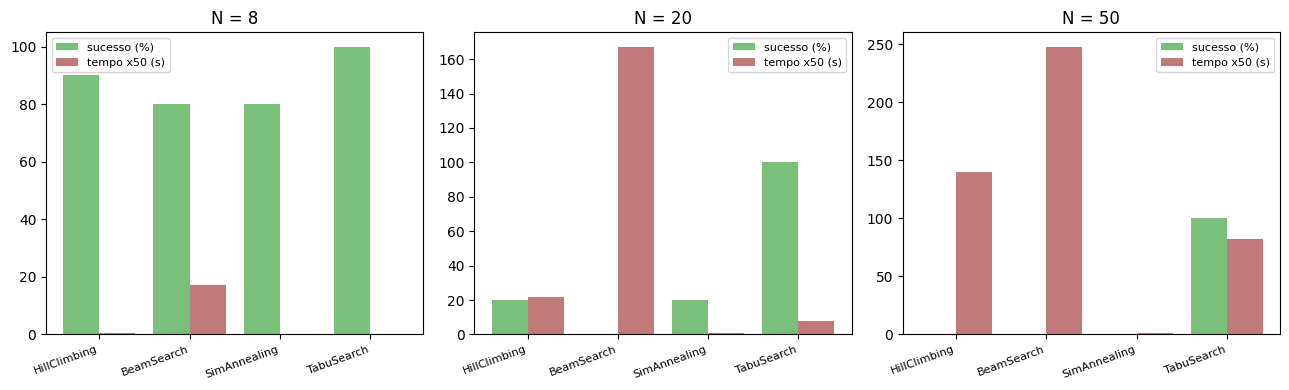

In [ ]:
#3 plots lado a lado, um por N
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, N in zip(axes, [8, 20, 50]):
    sub = df_nq[df_nq["N"] == N]
    x = np.arange(len(sub))
    w = 0.4
    ax.bar(x - w/2, sub["Sucesso (%)"], width=w, label="sucesso (%)",
           color="#7AC07A")
    ax.bar(x + w/2, sub["Tempo medio (s)"] * 50, width=w,
           label="tempo x50 (s)", color="#C07A7A")
    ax.set_xticks(x)
    ax.set_xticklabels(sub["Algoritmo"], rotation=20, ha="right", fontsize=8)
    ax.set_title(f"N = {N}")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("plots/nqueens_compare.png", dpi=110)
plt.show()

### B.7 Discussão

Tabu Search: Vencedor indiscutível (100% de sucesso em N=8, 20 e 50). A combinação de memória de movimentos (tabu list), critério de aspiração e restart suave constitui uma estratégia altamente robusta para contornar mínimos locais.

Hill Climbing: Colapsa rapidamente com o aumento da complexidade (sucesso cai de 90% em N=8 para 20% em N=20, e 0% em N=50). Confirma a forte estagnação em mínimos locais, demonstrando que o restart cego é insuficiente.

Simulated Annealing: Atingiu resultados modestos (0% de sucesso em N=50). A parametrização restritiva (arrefecimento rápido), necessária para manter tempos aceitáveis, impediu a exploração abrangente exigida em instâncias maiores.

Stochastic Beam Search: Registou o pior desempenho, com zero sucesso e severa degradação da qualidade em tabuleiros maiores. Este colapso reflete a redução forçada do beam_width em N=50; um aumento da largura ajudaria na procura, mas tornaria o custo computacional inviável.

## Problema 2 — Método Simplex

Objetivo: maximizar o lucro do restaurante.

$$
\max\ z = 6 x_1 + 7 x_2 + 6 x_3
$$

sujeito a:

$$
\begin{cases}
x_1 + 2 x_2 + x_3 \le 60   & \text{(tempo)} \\
2 x_1 + x_2 + 3 x_3 \le 95  & \text{(ingredientes)} \\
2 x_1 + 2 x_2 + x_3 \le 70  & \text{(capacidade)} \\
x_1, x_2, x_3 \ge 0
\end{cases}
$$

Onde $x_1$ = pratos de frango, $x_2$ = massa vegetariana, $x_3$ = salmão.

### C.1 Forma standard

Para a aplicação do método Simplex, as desigualdades foram convertidas em igualdades através da introdução de variáveis de folga (s1, s2, s3), que representam a quantidade não utilizada de cada recurso.

In [ ]:
def build_problem():
    """tabela inicial do simplex."""
    A = np.array([
        [1.0, 2.0, 1.0, 1.0, 0.0, 0.0],   #tempo <= 60
        [2.0, 1.0, 3.0, 0.0, 1.0, 0.0],   #ingredientes <= 95
        [2.0, 2.0, 1.0, 0.0, 0.0, 1.0],   #capacidade <= 70
    ])
    b = np.array([60.0, 95.0, 70.0])
    c = np.array([6.0, 7.0, 6.0, 0.0, 0.0, 0.0])  #com folgas
    m, n = A.shape
    tab = np.zeros((m + 1, n + 1))
    tab[0, :n] = -c
    tab[1:, :n] = A
    tab[1:, -1] = b
    base = [3, 4, 5]   #folgas s1, s2, s3
    return tab, base, n, m

#mostrar tabela inicial como dataframe
def tab_to_df(tab, base, n):
    cols = [f"x{i+1}" if i < 3 else f"s{i-2}" for i in range(n)] + ["b"]
    rows = ["z"] + [f"x{base[i]+1}" if base[i] < 3 else f"s{base[i]-2}"
                    for i in range(len(base))]
    df = pd.DataFrame(tab, columns=cols, index=rows)
    return df.round(3)

tab, base, n_v, m_r = build_problem()
print("=== Tabela inicial ===")
tab_to_df(tab, base, n_v)

=== Tabela inicial ===


,x1,x2,x3,s1,s2,s3,b
z,-6.0,-7.0,-6.0,-0.0,-0.0,-0.0,0.0
s1,1.0,2.0,1.0,1.0,0.0,0.0,60.0
s2,2.0,1.0,3.0,0.0,1.0,0.0,95.0
s3,2.0,2.0,1.0,0.0,0.0,1.0,70.0


### C.2 Iterações

A função `simplex_step` faz uma iteração completa: identifica a coluna pivot (variável a entrar), a linha pivot (variável a sair, regra do menor rácio), e atualiza a tabela.

In [17]:
def simplex_step(tab, base, verbose=False):
    """uma iteracao do simplex. Devolve True se ainda ha trabalho."""
    obj = tab[0, :-1]
    if np.all(obj >= -1e-9):
        return False    # otimo
    pivot_col = int(np.argmin(obj))

    col = tab[1:, pivot_col]
    rhs = tab[1:, -1]
    ratios = np.array([rhs[i] / col[i] if col[i] > 1e-9 else np.inf
                       for i in range(len(col))])
    if np.all(np.isinf(ratios)):
        raise RuntimeError("problema ilimitado")
    pivot_row = int(np.argmin(ratios)) + 1

    if verbose:
        old_var = base[pivot_row - 1] + 1
        print(f"  -> entra x{pivot_col + 1}, sai (linha {pivot_row}, "
              f"era x{old_var})")

    tab[pivot_row] = tab[pivot_row] / tab[pivot_row, pivot_col]
    for r in range(tab.shape[0]):
        if r != pivot_row:
            tab[r] = tab[r] - tab[r, pivot_col] * tab[pivot_row]
    base[pivot_row - 1] = pivot_col
    return True

def simplex_solve(verbose=True, max_iters=20):
    tab, base, n_v, m_r = build_problem()
    if verbose:
        print("--- Tabela inicial ---")
        print(tab_to_df(tab, base, n_v).to_string())
    it = 0
    while it < max_iters:
        if verbose:
            print(f"\n--- iteracao {it + 1} ---")
        cont = simplex_step(tab, base, verbose=verbose)
        if not cont:
            if verbose:
                print("\nOtimo atingido.")
            break
        if verbose:
            print(tab_to_df(tab, base, n_v).to_string())
        it += 1
    sol = np.zeros(n_v)
    for i, idx in enumerate(base):
        sol[idx] = tab[i + 1, -1]
    return {"x": sol[:3], "slacks": sol[3:], "z": tab[0, -1],
            "iters": it, "tab": tab, "base": base}

resultado = simplex_solve(verbose=True)

--- Tabela inicial ---
     x1   x2   x3   s1   s2   s3     b
z  -6.0 -7.0 -6.0 -0.0 -0.0 -0.0   0.0
s1  1.0  2.0  1.0  1.0  0.0  0.0  60.0
s2  2.0  1.0  3.0  0.0  1.0  0.0  95.0
s3  2.0  2.0  1.0  0.0  0.0  1.0  70.0

--- iteracao 1 ---
  -> entra x2, sai (linha 1, era x4)
     x1   x2   x3   s1   s2   s3      b
z  -2.5  0.0 -2.5  3.5  0.0  0.0  210.0
x2  0.5  1.0  0.5  0.5  0.0  0.0   30.0
s2  1.5  0.0  2.5 -0.5  1.0  0.0   65.0
s3  1.0  0.0  0.0 -1.0  0.0  1.0   10.0

--- iteracao 2 ---
  -> entra x1, sai (linha 3, era x6)
     x1   x2   x3   s1   s2   s3      b
z   0.0  0.0 -2.5  1.0  0.0  2.5  235.0
x2  0.0  1.0  0.5  1.0  0.0 -0.5   25.0
s2  0.0  0.0  2.5  1.0  1.0 -1.5   50.0
x1  1.0  0.0  0.0 -1.0  0.0  1.0   10.0

--- iteracao 3 ---
  -> entra x3, sai (linha 2, era x5)
     x1   x2   x3   s1   s2   s3      b
z   0.0  0.0  0.0  2.0  1.0  1.0  285.0
x2  0.0  1.0  0.0  0.8 -0.2 -0.2   15.0
x3  0.0  0.0  1.0  0.4  0.4 -0.6   20.0
x1  1.0  0.0  0.0 -1.0  0.0  1.0   10.0

--- iterac

### C.3 Solução e interpretação

In [ ]:
print("=== SOLUCAO OTIMA ===")
print(f"  x1 (frango)  = {resultado['x'][0]:.4f}")
print(f"  x2 (massa)   = {resultado['x'][1]:.4f}")
print(f"  x3 (salmao)  = {resultado['x'][2]:.4f}")
print(f"\n  Folgas:")
print(f"  s1 (tempo)        = {resultado['slacks'][0]:.4f}")
print(f"  s2 (ingredientes) = {resultado['slacks'][1]:.4f}")
print(f"  s3 (capacidade)   = {resultado['slacks'][2]:.4f}")
print(f"\n  Lucro otimo z = {resultado['z']:.2f} EUR")

#verificação manual rápida
x1, x2, x3 = resultado['x']
print(f"\nverif: 6*{x1:.0f}+7*{x2:.0f}+6*{x3:.0f} = "
      f"{6*x1+7*x2+6*x3:.0f} EUR  (esperado 285)")

=== SOLUCAO OTIMA ===
  x1 (frango)  = 10.0000
  x2 (massa)   = 15.0000
  x3 (salmao)  = 20.0000

  Folgas:
  s1 (tempo)        = 0.0000
  s2 (ingredientes) = 0.0000
  s3 (capacidade)   = 0.0000

  Lucro otimo z = 285.00 EUR

verif: 6*10+7*15+6*20 = 285 EUR  (esperado 285)


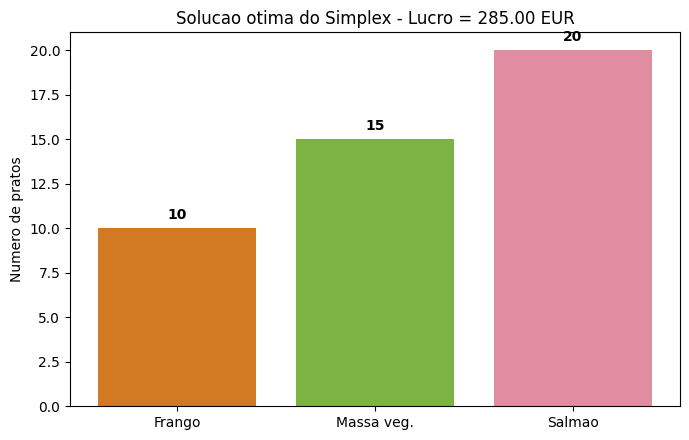

In [ ]:
#plot da solução
fig, ax = plt.subplots(figsize=(7, 4.5))
nomes = ["Frango", "Massa veg.", "Salmao"]
qts = resultado['x']
bars = ax.bar(nomes, qts, color=["#D17A22", "#7CB342", "#E08CA1"])
ax.set_ylabel("Numero de pratos")
ax.set_title(f"Solucao otima do Simplex - Lucro = {resultado['z']:.2f} EUR")
for bar, q in zip(bars, qts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f"{q:.0f}", ha="center", fontweight="bold")
plt.tight_layout()
plt.savefig("plots/simplex_solucao.png", dpi=110)
plt.show()

**Interpretação**

A solução alcançada provou que é possível maximizar o lucro diário para 285 €, determinando com exatidão o mix de produção ideal (10 pratos de frango, 15 de massa e 20 de salmão). Mais do que calcular um valor financeiro, o modelo revelou um cenário de eficiência operacional perfeita, onde todo o tempo de preparação, ingredientes frescos e capacidade de empratamento são esgotados sem qualquer desperdício (variáveis de folga nulas no ótimo). 

## Conclusão

No Problema 1, a análise confirmou que a escalabilidade é o principal obstáculo computacional. No 8-puzzle, o algoritmo A* equipado com a heurística de Manhattan controlou a explosão combinatória, garantindo a solução ótima sem exaustão de memória. Paralelamente, nas N-Rainhas, o Tabu Search provou que a inclusão de mecanismos de diversificação é vital para superar os mínimos locais que limitam severamente as abordagens gulosas.

A resolução do Problema 2 ilustrou o enorme potencial da Programação Linear na otimização estrita de recursos físicos limitados. A aplicação do método Simplex permitiu a tradução de variáveis e restrições operacionais num modelo matemático rigoroso. Este processo provou que a formulação matemática constitui uma ferramenta analítica de excelência, suportando de forma exata e inequívoca a tomada de decisão para a maximização do lucro empresarial.

Globalmente, a avaliação metodológica transversal a estas experiências reforça o princípio de que não existe um algoritmo universal. O sucesso da resolução exige sempre uma adequação rigorosa da técnica escolhida à natureza específica do desafio. Conclui-se, assim, que qualquer implementação deve ser meticulosamente ditada pela estrutura intrínseca do problema, pela exigência de otimalidade e pelas reais capacidades dos recursos computacionais disponíveis no sistema.